# Modelagem de IA da FarmTech Solutions
### Recomendação de culturas a partir das condições de solo e clima

**FIAP · Graduação em Inteligência Artificial · Turma 1TIAOR · Fase 3 · Capítulo 11**

**Integrantes:**
- Tiago Mendes Lanna — RM575734
- João Emanuel Hamacek de Paiva — RM575616
- Leandro de Oliveira Carvalho — RM576043

---

**Objetivo:** indicar ao produtor qual cultura plantar a partir das condições de solo e clima, usando a base `produtos_agricolas.csv` (2.200 registros de 22 culturas).

**Etapas:** 1. Preparação do ambiente · 2. Dados · 3. Análise exploratória · 4. Análise descritiva · 5. Perfil ideal (café, milho e feijão) · 6. Modelos preditivos · 7. Conclusões

**Por que café, milho e feijão?** Café e milho vêm das fases anteriores da FarmTech; o feijão (*kidneybeans*) representa as leguminosas, já que a soja não está na base.

### Resultados em resumo
- **Base:** limpa e balanceada. Umidade do ar, chuva e nitrogênio são as variáveis que mais diferenciam as culturas.
- **Perfil ideal geral:** N ≈ 37, P ≈ 51, K ≈ 32, 25,6 °C, 80% de umidade do ar, pH 6,4 e 95 mm de chuva. O café pede mais nitrogênio e chuva; o milho é o mais próximo do perfil geral; o feijão é o mais distante (ar seco, clima ameno e solo ácido).
- **Modelos:** os cinco passaram de 98% de acurácia no teste. O melhor foi o **Random Forest**: 99,8% de acurácia, com 1 erro em 440 amostras.

## 1. Preparação do ambiente

Bibliotecas: **pandas** e **NumPy** (dados), **Matplotlib** e **Seaborn** (gráficos), **SciPy** (testes estatísticos) e **scikit-learn** (modelos). A semente aleatória fixa garante os mesmos resultados a cada execução.

**Como executar:** deixe o arquivo `produtos_agricolas.csv` na mesma pasta do notebook e use *Kernel → Restart & Run All* (cerca de 1 minuto).

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, top_k_accuracy_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
SEMENTE = 42  # reprodutibilidade
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 30)

# Identidade visual: paleta segura para daltonismo; cada cultura destacada tem sempre a mesma cor.
CINZA, TINTA2, GRADE, NEUTRO = "#c3c2b7", "#52514e", "#e1e0d9", "#f0efec"
AZUL = "#2a78d6"
CORES_DESTAQUE = {"café": "#2a78d6", "milho": "#eb6834", "feijão": "#1baf7a"}
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", ["#184f95", "#6da7ec", NEUTRO, "#ef8f8e", "#b8302f"])
SEQUENCIAL = LinearSegmentedColormap.from_list("sequencial", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": CINZA, "grid.color": GRADE, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "figure.dpi": 100, "legend.frameon": False})

print(f"pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__} | seaborn {sns.__version__}")

pandas 3.0.5 | NumPy 2.5.3 | scikit-learn 1.9.1 | seaborn 0.13.2


## 2. Dados

| Coluna | Significado | Unidade |
|---|---|---|
| `N`, `P`, `K` | nitrogênio, fósforo e potássio no solo | valor relativo (a base não informa a unidade) |
| `temperature` | temperatura média da região | °C |
| `humidity` | umidade relativa média do ar | % |
| `ph` | pH do solo | 0 a 14 |
| `rainfall` | precipitação | mm |
| `label` | cultura plantada naquelas condições | 22 culturas |

Os nomes das culturas foram traduzidos para o português (`kidneybeans` = feijão, `coffee` = café, `maize` = milho etc.).

In [2]:
CANDIDATOS = ["produtos_agricolas.csv", "Atividade_Cap11_produtos_agricolas.csv"]
arquivo = next((Path(c) for c in CANDIDATOS if Path(c).exists()), None)
if arquivo is None:
    raise FileNotFoundError("Coloque o arquivo produtos_agricolas.csv na mesma pasta deste notebook.")
df = pd.read_csv(arquivo)

VARIAVEIS = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
NOMES_PT = {"N": "nitrogênio (N)", "P": "fósforo (P)", "K": "potássio (K)", "temperature": "temperatura (°C)",
            "humidity": "umidade do ar (%)", "ph": "pH do solo", "rainfall": "chuva (mm)"}
CULTURAS_PT = {
    "rice": "arroz", "maize": "milho", "chickpea": "grão-de-bico", "kidneybeans": "feijão",
    "pigeonpeas": "feijão-guandu", "mothbeans": "feijão-moth", "mungbean": "feijão-mungo",
    "blackgram": "feijão-urd", "lentil": "lentilha", "pomegranate": "romã", "banana": "banana",
    "mango": "manga", "grapes": "uva", "watermelon": "melancia", "muskmelon": "melão", "apple": "maçã",
    "orange": "laranja", "papaya": "mamão", "coconut": "coco", "cotton": "algodão", "jute": "juta",
    "coffee": "café"}
df["cultura"] = df["label"].map(CULTURAS_PT)
ESCOLHIDAS = ["café", "milho", "feijão"]

print(f"Arquivo: {arquivo.name} | {df.shape[0]} linhas | {len(VARIAVEIS)} variáveis numéricas + rótulo")
df.head()

Arquivo: produtos_agricolas.csv | 2200 linhas | 7 variáveis numéricas + rótulo


,N,P,K,temperature,humidity,ph,rainfall,label,cultura
0,90,42,43,20.88,82.00,6.50,202.94,rice,arroz
1,85,58,41,21.77,80.32,7.04,226.66,rice,arroz
2,60,55,44,23.00,82.32,7.84,263.96,rice,arroz
3,74,35,40,26.49,80.16,6.98,242.86,rice,arroz
4,78,42,42,20.13,81.60,7.63,262.72,rice,arroz


## 3. Análise exploratória

Verificamos estrutura e qualidade dos dados: tipos, valores ausentes, duplicatas, balanceamento, distribuições e valores extremos.

In [3]:
colunas = VARIAVEIS + ["label"]
qualidade = pd.DataFrame({
    "tipo": df[colunas].dtypes.astype(str),
    "valores ausentes": df[colunas].isna().sum(),
    "valores distintos": df[colunas].nunique(),
})
amostras = df["cultura"].value_counts()
print(f"Linhas duplicadas: {df.duplicated(subset=colunas).sum()}")
print(f"Culturas: {amostras.size} | amostras por cultura: mínimo {amostras.min()}, máximo {amostras.max()}")
qualidade

Linhas duplicadas: 0
Culturas: 22 | amostras por cultura: mínimo 100, máximo 100


,tipo,valores ausentes,valores distintos
N,int64,0,137
P,int64,0,117
K,int64,0,73
temperature,float64,0,2200
humidity,float64,0,2200
ph,float64,0,2200
rainfall,float64,0,2200
label,str,0,22


In [4]:
resumo = df[VARIAVEIS].describe().T
resumo["assimetria"] = df[VARIAVEIS].skew()
resumo.rename(index=NOMES_PT)

,count,mean,std,min,25%,50%,75%,max,assimetria
nitrogênio (N),2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00,0.51
fósforo (P),2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00,1.01
potássio (K),2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00,2.38
temperatura (°C),2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68,0.18
umidade do ar (%),2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98,-1.09
pH do solo,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94,0.28
chuva (mm),2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56,0.97


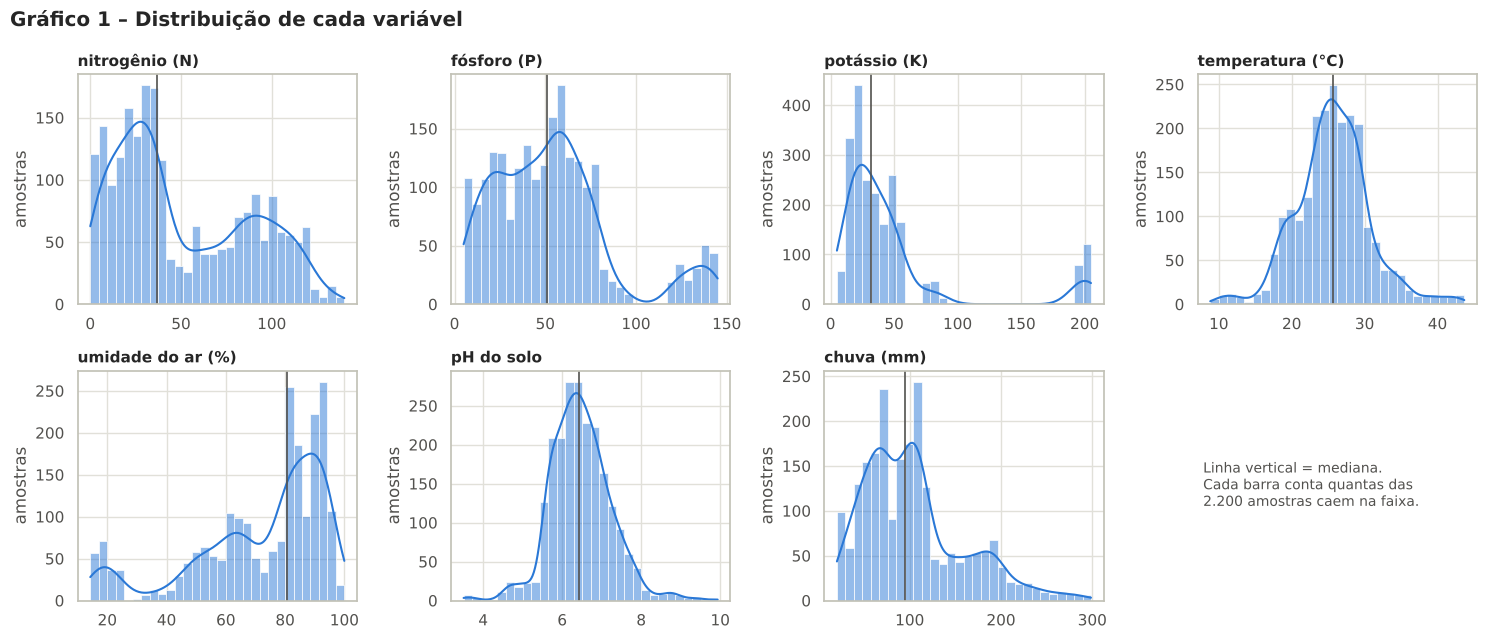

In [5]:
fig, eixos = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, var in zip(eixos.flat, VARIAVEIS):
    sns.histplot(df[var], bins=30, kde=True, color=AZUL, edgecolor="white", linewidth=0.5, ax=ax)
    ax.axvline(df[var].median(), color=TINTA2, lw=1.2)
    ax.set_title(NOMES_PT[var])
    ax.set_xlabel("")
    ax.set_ylabel("amostras")
eixos.flat[-1].axis("off")
eixos.flat[-1].text(0.02, 0.5, "Linha vertical = mediana.\nCada barra conta quantas das\n2.200 amostras caem na faixa.",
                    fontsize=10, color=TINTA2, va="center")
fig.suptitle("Gráfico 1 – Distribuição de cada variável", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [6]:
# Valores extremos pela regra do intervalo interquartil (IQR): abaixo de Q1 - 1,5*IQR ou acima de Q3 + 1,5*IQR
q1, q3 = df[VARIAVEIS].quantile(0.25), df[VARIAVEIS].quantile(0.75)
iqr = q3 - q1
fora = (df[VARIAVEIS] < q1 - 1.5 * iqr) | (df[VARIAVEIS] > q3 + 1.5 * iqr)
pd.DataFrame({
    "valores extremos (IQR)": fora.sum(),
    "culturas responsáveis (quantidade)": [
        ", ".join(f"{c} ({n})" for c, n in df.loc[fora[v], "cultura"].value_counts().head(3).items()) or "—"
        for v in VARIAVEIS],
}).rename(index=NOMES_PT)

,valores extremos (IQR),culturas responsáveis (quantidade)
nitrogênio (N),0,—
fósforo (P),138,"maçã (70), uva (68)"
potássio (K),200,"uva (100), maçã (100)"
temperatura (°C),86,"mamão (35), uva (34), laranja (17)"
umidade do ar (%),30,grão-de-bico (30)
pH do solo,57,"feijão-moth (42), grão-de-bico (13), manga (2)"
chuva (mm),100,"arroz (68), mamão (17), coco (15)"


### O que a análise exploratória mostrou

- **Base limpa e balanceada:** sem valores ausentes nem duplicatas, com 100 amostras por cultura. Nada precisou ser removido ou imputado, e a acurácia pode ser usada como métrica sem distorção.
- **Escalas muito diferentes** (K de 5 a 205, chuva de 20 a 299 mm, pH de 3,5 a 9,9): KNN, SVM e Regressão Logística precisam de padronização.
- **Assimetria:** K, P e chuva têm cauda longa à direita; a umidade tem cauda à esquerda, com metade das amostras acima de 80%.
- **Os valores extremos não são erros:** vêm de culturas exigentes (maçã e uva em P e K, arroz em chuva, mamão e uva em temperatura, grão-de-bico em umidade, feijão-moth em pH). Foram mantidos, porque são justamente o que diferencia essas culturas.

## 4. Análise descritiva: principais achados

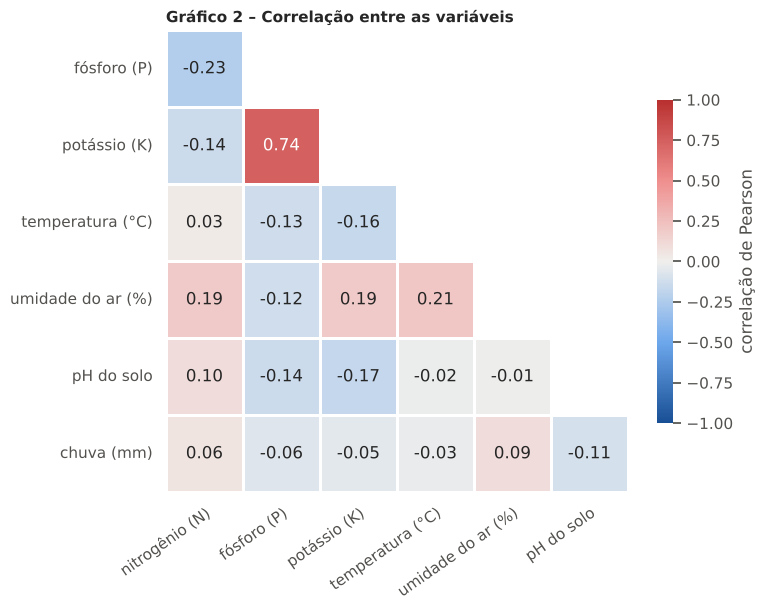

P x K: Pearson = 0.74 | Spearman (por postos) = 0.20


In [7]:
corr = df[VARIAVEIS].corr().rename(index=NOMES_PT, columns=NOMES_PT)
triangulo = corr.iloc[1:, :-1]  # sem a diagonal (sempre 1)
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(triangulo, mask=np.triu(np.ones_like(triangulo, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap=DIVERGENTE, vmin=-1, vmax=1, center=0, square=True, linewidths=2, linecolor="white",
            cbar_kws={"shrink": 0.7, "label": "correlação de Pearson"}, ax=ax)
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")
ax.set_title("Gráfico 2 – Correlação entre as variáveis")
plt.show()
print(f"P x K: Pearson = {df['P'].corr(df['K']):.2f} | Spearman (por postos) = {df['P'].corr(df['K'], method='spearman'):.2f}")

**Achado 1 — as variáveis são quase independentes.** As correlações ficam entre −0,25 e 0,25, com uma exceção: **fósforo × potássio (0,74)**. Pela correlação de Spearman ela cai para 0,20, sinal de que vem de um grupo pequeno de amostras (Gráfico 3).

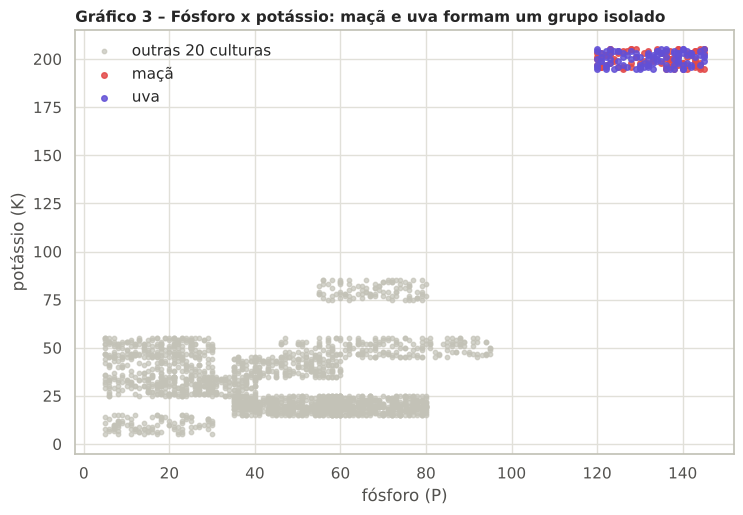

Correlação P x K sem maçã e uva: 0.04


In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
outras = df[~df["cultura"].isin(["maçã", "uva"])]
ax.scatter(outras["P"], outras["K"], s=10, color=CINZA, alpha=0.7, label="outras 20 culturas")
for cultura, cor in [("maçã", "#e34948"), ("uva", "#6250d6")]:
    sub = df[df["cultura"] == cultura]
    ax.scatter(sub["P"], sub["K"], s=16, color=cor, alpha=0.85, label=cultura)
ax.set_xlabel("fósforo (P)")
ax.set_ylabel("potássio (K)")
ax.set_title("Gráfico 3 – Fósforo x potássio: maçã e uva formam um grupo isolado")
ax.legend(loc="upper left")
plt.show()
print(f"Correlação P x K sem maçã e uva: {outras['P'].corr(outras['K']):.2f}")

**Achado 2 — maçã e uva explicam a correlação entre P e K.** As duas exigem fósforo (≈135) e potássio (≈200) muito acima das demais e formam um bloco isolado; sem elas, a correlação cai para 0,04. Aqui, correlação alta não indica uma relação geral, e sim um grupo de culturas com exigência parecida.

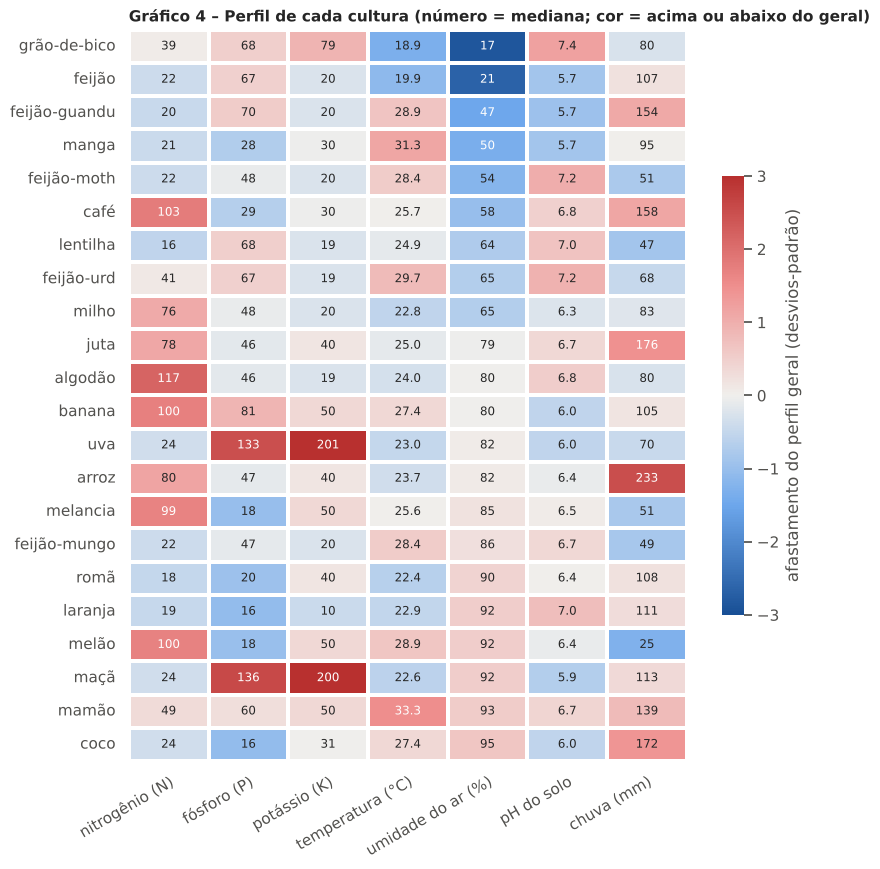

In [9]:
medianas = df.groupby("cultura")[VARIAVEIS].median()
z_cultura = (medianas - df[VARIAVEIS].median()) / df[VARIAVEIS].std()   # quanto cada cultura se afasta do geral
ordem_umidade = medianas["humidity"].sort_values().index
casas = {"N": 0, "P": 0, "K": 0, "temperature": 1, "humidity": 0, "ph": 1, "rainfall": 0}
rotulos = medianas.loc[ordem_umidade].apply(lambda col: col.map(lambda v: f"{v:.{casas[col.name]}f}"))

fig, ax = plt.subplots(figsize=(9, 9.5))
sns.heatmap(z_cultura.loc[ordem_umidade].rename(columns=NOMES_PT), annot=rotulos.values, fmt="", cmap=DIVERGENTE,
            center=0, vmin=-3, vmax=3, linewidths=1.5, linecolor="white", annot_kws={"fontsize": 8.5},
            cbar_kws={"shrink": 0.6, "label": "afastamento do perfil geral (desvios-padrão)"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
ax.set_title("Gráfico 4 – Perfil de cada cultura (número = mediana; cor = acima ou abaixo do geral)")
plt.show()

In [10]:
# As culturas diferem de fato? Teste de Kruskal-Wallis (não paramétrico) entre as 22 culturas, variável por variável
kw_22 = {NOMES_PT[v]: stats.kruskal(*[g[v].values for _, g in df.groupby("cultura")]) for v in VARIAVEIS}
pd.DataFrame({"estatística H": {k: r.statistic for k, r in kw_22.items()},
              "p-valor": {k: (f"{r.pvalue:.1e}" if r.pvalue > 0 else "< 1e-300") for k, r in kw_22.items()}})

,estatística H,p-valor
nitrogênio (N),1765.36,< 1e-300
fósforo (P),2007.18,< 1e-300
potássio (K),2065.96,< 1e-300
temperatura (°C),1317.27,4.9e-266
umidade do ar (%),2080.32,< 1e-300
pH do solo,1019.87,1.6e-202
chuva (mm),1944.98,< 1e-300


**Achado 3 — cada cultura tem uma "assinatura" de solo e clima.** O teste de Kruskal-Wallis confirma diferença entre as 22 culturas em todas as variáveis (p < 10⁻²⁰⁰). No Gráfico 4 (vermelho = acima do perfil geral; azul = abaixo):

- **ar muito seco:** grão-de-bico (≈17%) e feijão (≈21%);
- **muita chuva:** arroz (≈233 mm), juta, coco, café e feijão-guandu (acima de 150 mm); **pouca chuva:** melão (≈25 mm), lentilha, feijão-mungo, melancia e feijão-moth;
- **muito nitrogênio:** algodão (≈117), café, banana, melão e melancia (≈100). As leguminosas pedem pouco N (16 a 41), porque fixam nitrogênio do ar;
- **calor:** mamão (≈33 °C) e manga (≈31 °C); **clima ameno:** grão-de-bico e feijão (≈19 a 20 °C);
- **pH:** feijão, manga e feijão-guandu em solo mais ácido (≈5,7); grão-de-bico, feijão-urd e feijão-moth em solo neutro a alcalino (≈7,2 a 7,4).

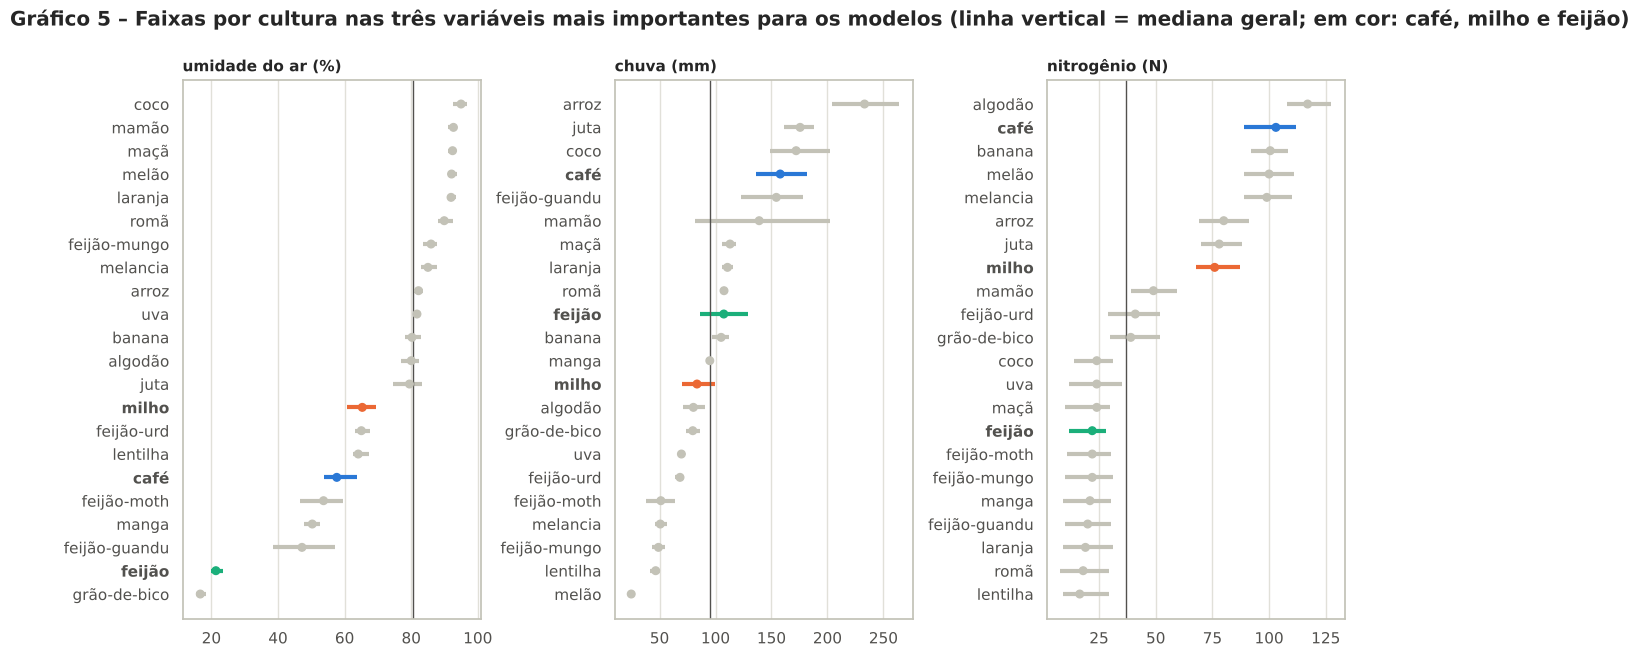

In [11]:
def faixas_por_cultura(var, ax):
    # Ponto = mediana; barra = faixa central (25% a 75% das amostras) de cada cultura.
    est = df.groupby("cultura")[var].quantile([0.25, 0.5, 0.75]).unstack().sort_values(0.5)
    cores = [CORES_DESTAQUE.get(c, CINZA) for c in est.index]
    ax.hlines(est.index, est[0.25], est[0.75], color=cores, lw=3)
    ax.scatter(est[0.5], est.index, color=cores, s=30, zorder=3)
    ax.axvline(df[var].median(), color=TINTA2, lw=1)
    ax.set_title(NOMES_PT[var])
    ax.grid(axis="y", visible=False)
    for rotulo in ax.get_yticklabels():
        if rotulo.get_text() in ESCOLHIDAS:
            rotulo.set_fontweight("bold")

fig, eixos = plt.subplots(1, 3, figsize=(15, 7), gridspec_kw={"wspace": 0.45})
for ax, var in zip(eixos, ["humidity", "rainfall", "N"]):
    faixas_por_cultura(var, ax)
fig.suptitle("Gráfico 5 – Faixas por cultura nas três variáveis mais importantes para os modelos "
             "(linha vertical = mediana geral; em cor: café, milho e feijão)", x=0.01, ha="left", fontweight="bold")
plt.show()

**Achado 4 — em umidade, chuva e nitrogênio as faixas quase não se sobrepõem.** São as três variáveis que mais pesam nos modelos (seção 6.6). Grão-de-bico e feijão ficam isolados na umidade mais baixa, o arroz na chuva mais alta e o algodão no topo do nitrogênio. Já feijão-urd, feijão-mungo, feijão-moth e lentilha dividem faixas parecidas, o que antecipa onde os modelos podem errar.

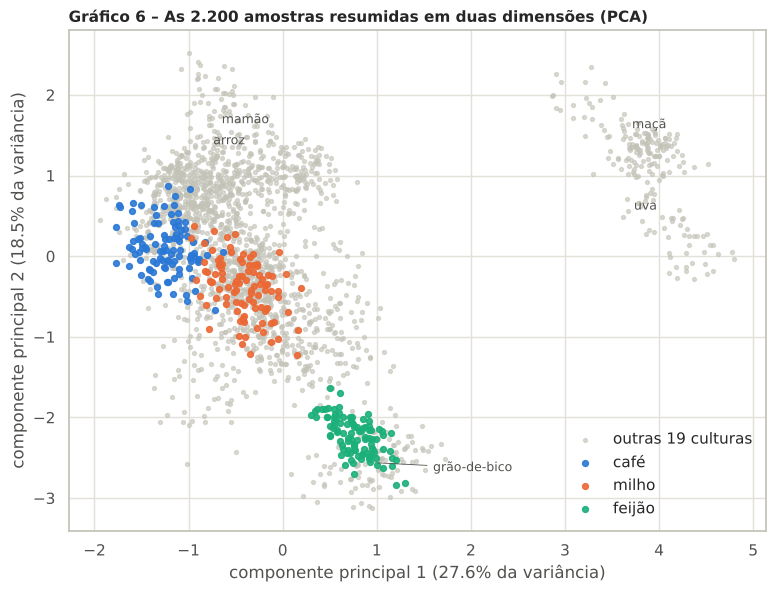

In [12]:
componentes = PCA(n_components=2, random_state=SEMENTE)
pontos = componentes.fit_transform(StandardScaler().fit_transform(df[VARIAVEIS]))
proj = pd.DataFrame(pontos, columns=["PC1", "PC2"]).assign(cultura=df["cultura"])

fig, ax = plt.subplots(figsize=(9, 6.5))
resto = proj[~proj["cultura"].isin(ESCOLHIDAS)]
ax.scatter(resto["PC1"], resto["PC2"], s=8, color=CINZA, alpha=0.6, label="outras 19 culturas")
for cultura in ESCOLHIDAS:
    sub = proj[proj["cultura"] == cultura]
    ax.scatter(sub["PC1"], sub["PC2"], s=18, color=CORES_DESTAQUE[cultura], alpha=0.9, label=cultura)
deslocamentos = {"maçã": (0, 14), "uva": (0, -16), "grão-de-bico": (70, -6), "arroz": (0, 14), "mamão": (0, 14)}
for cultura, desloc in deslocamentos.items():
    centro = proj[proj["cultura"] == cultura][["PC1", "PC2"]].mean()
    ax.annotate(cultura, centro, fontsize=9, color=TINTA2, ha="center", xytext=desloc, textcoords="offset points",
                arrowprops={"arrowstyle": "-", "color": TINTA2, "lw": 0.6} if cultura == "grão-de-bico" else None)
var1, var2 = componentes.explained_variance_ratio_ * 100
ax.set_xlabel(f"componente principal 1 ({var1:.1f}% da variância)")
ax.set_ylabel(f"componente principal 2 ({var2:.1f}% da variância)")
ax.set_title("Gráfico 6 – As 2.200 amostras resumidas em duas dimensões (PCA)")
ax.legend(loc="lower right")
plt.show()

**Achado 5 — há grupos bem separados, mas duas dimensões não bastam.** A PCA guarda 46% da variação em 2 eixos. Maçã e uva ficam isoladas à direita, feijão e grão-de-bico (ar seco) embaixo e o café na borda esquerda. O milho fica no centro, misturado a outras culturas, coerente com ser uma das mais próximas do perfil geral (seção 5). Como mais da metade da informação se perde em 2 eixos, os modelos usam as 7 variáveis.

## 5. Perfil ideal e comparação de café, milho e feijão

Cada linha da base registra condições em que a cultura é recomendada. Assim:
- **perfil ideal de cada cultura** = mediana e faixa central (percentis 25 a 75) das suas 100 amostras;
- **perfil ideal geral** = o mesmo cálculo com as 2.200 amostras, usado como **régua de comparação**.

Em cada variável, comparamos a cultura com as outras 21 pelo teste de **Mann-Whitney** (não exige distribuição normal) e medimos o tamanho do efeito pelo **delta de Cliff**: vai de −1 a +1, é positivo quando a cultura tem valores maiores e é classificado como desprezível (< 0,147), pequeno (< 0,33), médio (< 0,474) ou grande. O teste de **Kruskal-Wallis** verifica se os três perfis diferem entre si.

In [13]:
perfil_geral = pd.DataFrame({
    "mediana": df[VARIAVEIS].median(),
    "faixa ideal: de (P25)": df[VARIAVEIS].quantile(0.25),
    "faixa ideal: até (P75)": df[VARIAVEIS].quantile(0.75),
}).rename(index=NOMES_PT)
print("Perfil ideal geral (todas as 22 culturas)")
perfil_geral

Perfil ideal geral (todas as 22 culturas)


,mediana,faixa ideal: de (P25),faixa ideal: até (P75)
nitrogênio (N),37.00,21.00,84.25
fósforo (P),51.00,28.00,68.00
potássio (K),32.00,20.00,49.00
temperatura (°C),25.60,22.77,28.56
umidade do ar (%),80.47,60.26,89.95
pH do solo,6.43,5.97,6.92
chuva (mm),94.87,64.55,124.27


In [14]:
CASAS = {"N": 0, "P": 0, "K": 0, "temperature": 1, "humidity": 0, "ph": 2, "rainfall": 0}

def faixa_texto(serie, casas):
    return f"{serie.median():.{casas}f} ({serie.quantile(0.25):.{casas}f} a {serie.quantile(0.75):.{casas}f})"

perfil_cultura = pd.DataFrame({
    NOMES_PT[v]: df.groupby("cultura")[v].agg(lambda s, c=CASAS[v]: faixa_texto(s, c)) for v in VARIAVEIS})
print("Perfil ideal de cada cultura: mediana (faixa central P25 a P75)")
perfil_cultura

Perfil ideal de cada cultura: mediana (faixa central P25 a P75)


,nitrogênio (N),fósforo (P),potássio (K),temperatura (°C),umidade do ar (%),pH do solo,chuva (mm)
cultura,,,,,,,
algodão,117 (108 a 128),46 (40 a 52),19 (17 a 22),24.0 (23.0 a 25.0),80 (77 a 82),6.84 (6.36 a 7.43),80 (71 a 90)
arroz,80 (69 a 91),47 (41 a 54),40 (38 a 42),23.7 (21.9 a 25.5),82 (81 a 83),6.36 (5.87 a 7.04),233 (204 a 264)
banana,100 (92 a 108),81 (75 a 88),50 (47 a 53),27.4 (26.1 a 28.7),80 (78 a 83),5.99 (5.74 a 6.21),105 (96 a 112)
café,103 (89 a 112),29 (23 a 34),30 (27 a 33),25.7 (24.2 a 26.7),58 (54 a 64),6.80 (6.43 a 7.13),158 (136 a 181)
coco,24 (14 a 31),16 (10 a 24),31 (29 a 33),27.4 (26.3 a 28.6),95 (93 a 97),5.99 (5.73 a 6.21),172 (149 a 202)
feijão,22 (12 a 28),67 (61 a 74),20 (17 a 22),19.9 (18.3 a 22.0),21 (20 a 23),5.75 (5.62 a 5.87),107 (86 a 129)
feijão-guandu,20 (10 a 30),70 (61 a 73),20 (18 a 23),28.9 (22.9 a 31.5),47 (38 a 57),5.69 (5.00 a 6.42),154 (122 a 178)
feijão-moth,22 (11 a 30),48 (43 a 55),20 (18 a 23),28.4 (26.4 a 30.1),54 (47 a 59),7.22 (5.38 a 8.37),51 (38 a 64)
feijão-mungo,22 (10 a 31),47 (40 a 54),20 (17 a 22),28.4 (27.9 a 29.2),86 (83 a 88),6.70 (6.47 a 6.98),49 (43 a 55)


In [15]:
def delta_cliff(u, n1, n2):
    return 2 * u / (n1 * n2) - 1   # equivale à correlação rank-bisserial do teste de Mann-Whitney

def magnitude(d):
    a = abs(d)
    return "desprezível" if a < 0.147 else "pequeno" if a < 0.33 else "médio" if a < 0.474 else "grande"

linhas = []
for cultura in ESCOLHIDAS:
    grupo, demais = df[df["cultura"] == cultura], df[df["cultura"] != cultura]
    for v in VARIAVEIS:
        u, p = stats.mannwhitneyu(grupo[v], demais[v], alternative="two-sided")
        d = delta_cliff(u, len(grupo), len(demais))
        diferente = p < 0.05 and abs(d) >= 0.147
        linhas.append({
            "cultura": cultura, "variável": NOMES_PT[v],
            "mediana da cultura": grupo[v].median(), "mediana geral": df[v].median(),
            "z": (grupo[v].median() - df[v].median()) / df[v].std(),
            "p-valor": p, "delta de Cliff": d, "efeito": magnitude(d),
            "conclusão": ("maior" if d > 0 else "menor") if diferente else "igual ao geral"})
comparacao = pd.DataFrame(linhas)

setas = comparacao.assign(resumo=lambda t: np.where(
    t["conclusão"] == "igual ao geral", "≈ igual",
    np.where(t["conclusão"] == "maior", "▲ ", "▼ ") + t["conclusão"] + " (" + t["efeito"] + ")"))
print("Cada cultura comparada ao perfil geral (Mann-Whitney, α = 5%, efeito pelo delta de Cliff)")
setas.pivot(index="variável", columns="cultura", values="resumo").loc[list(NOMES_PT.values()), ESCOLHIDAS]

Cada cultura comparada ao perfil geral (Mann-Whitney, α = 5%, efeito pelo delta de Cliff)


cultura,café,milho,feijão
variável,,,
nitrogênio (N),▲ maior (grande),▲ maior (médio),▼ menor (grande)
fósforo (P),▼ menor (grande),≈ igual,▲ maior (grande)
potássio (K),≈ igual,▼ menor (grande),▼ menor (grande)
temperatura (°C),≈ igual,▼ menor (médio),▼ menor (grande)
umidade do ar (%),▼ menor (grande),▼ menor (médio),▼ menor (grande)
pH do solo,▲ maior (médio),▼ menor (pequeno),▼ menor (grande)
chuva (mm),▲ maior (grande),▼ menor (pequeno),▲ maior (pequeno)


In [16]:
# Detalhe dos testes: medianas, p-valor e tamanho do efeito
detalhe = comparacao[["cultura", "variável", "mediana da cultura", "mediana geral", "p-valor", "delta de Cliff", "efeito"]].copy()
detalhe["p-valor"] = detalhe["p-valor"].map(lambda p: f"{p:.1e}")
detalhe.round({"mediana da cultura": 2, "mediana geral": 2, "delta de Cliff": 2}).set_index(["cultura", "variável"])

mediana da cultura  mediana geral  p-valor  \
cultura variável                                                        
café    nitrogênio (N)                 103.00          37.00  1.3e-37   
        fósforo (P)                     29.00          51.00  7.8e-19   
        potássio (K)                    30.00          32.00  3.6e-01   
        temperatura (°C)                25.66          25.60  7.4e-01   
        umidade do ar (%)               57.65          80.47  1.6e-18   
        pH do solo                       6.80           6.43  7.0e-09   
        chuva (mm)                     157.77          94.87  5.0e-31   
milho   nitrogênio (N)                  76.00          37.00  1.2e-14   
        fósforo (P)                     48.50          51.00  4.3e-01   
        potássio (K)                    20.00          32.00  3.7e-22   
        temperatura (°C)                22.84          25.60  1.7e-15   
        umidade do ar (%)               65.30          80.47  3.2e-10   
        pH do solo                       6.26           6.43  8.4e-04   
        chuva (mm)                      83.47          94.87  1.0e-02   
feijão  nitrogênio (N)                  22.00          37.00  6.4e-17   
        fósforo (P)                     67.00          51.00  7.2e-17   
        potássio (K)                    20.00          32.00  8.0e-21   
        temperatura (°C)                19.92          25.60  1.7e-34   
        umidade do ar (%)               21.35          80.47  2.2e-53   
        pH do solo                       5.75           6.43  9.3e-35   
        chuva (mm)                     107.40          94.87  5.8e-03   

                           delta de Cliff       efeito  
cultura variável                                        
café    nitrogênio (N)               0.76       grande  
        fósforo (P)                 -0.52       grande  
        potássio (K)                -0.05  desprezível  
        temperatura (°C)            -0.02  desprezível  
        umidade do ar (%)           -0.52       grande  
        pH do solo                   0.34        médio  
        chuva (mm)                   0.68       grande  
milho   nitrogênio (N)               0.46        médio  
        fósforo (P)                 -0.05  desprezível  
        potássio (K)                -0.57       grande  
        temperatura (°C)            -0.47        médio  
        umidade do ar (%)           -0.37        médio  
        pH do solo                  -0.20      pequeno  
        chuva (mm)                  -0.15      pequeno  
feijão  nitrogênio (N)              -0.49       grande  
        fósforo (P)                  0.49       grande  
        potássio (K)                -0.55       grande  
        temperatura (°C)            -0.72       grande  
        umidade do ar (%)           -0.91       grande  
        pH do solo                  -0.73       grande  
        chuva (mm)                   0.16      pequeno

In [17]:
kruskal = {NOMES_PT[v]: stats.kruskal(*[df.loc[df["cultura"] == c, v] for c in ESCOLHIDAS]) for v in VARIAVEIS}
print("Kruskal-Wallis entre café, milho e feijão")
pd.DataFrame({"estatística H": {k: r.statistic for k, r in kruskal.items()},
              "p-valor": {k: f"{r.pvalue:.1e}" for k, r in kruskal.items()}})

Kruskal-Wallis entre café, milho e feijão


,estatística H,p-valor
nitrogênio (N),242.53,2.2e-53
fósforo (P),247.89,1.5e-54
potássio (K),197.98,1.0e-43
temperatura (°C),148.36,6.1e-33
umidade do ar (%),219.07,2.7e-48
pH do solo,182.19,2.7e-40
chuva (mm),187.46,2.0e-41


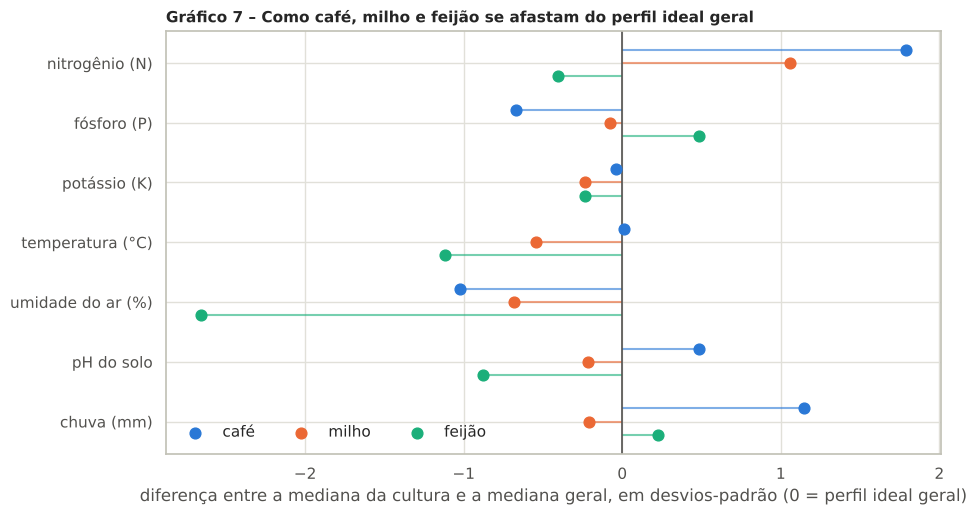

In [18]:
ordem_vars = list(NOMES_PT.values())
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, cultura in enumerate(ESCOLHIDAS):
    sub = comparacao[comparacao["cultura"] == cultura].set_index("variável").loc[ordem_vars]
    y = np.arange(len(ordem_vars)) + (i - 1) * 0.22
    ax.hlines(y, 0, sub["z"], color=CORES_DESTAQUE[cultura], lw=1.5, alpha=0.6)
    ax.scatter(sub["z"], y, color=CORES_DESTAQUE[cultura], s=60, zorder=3, label=cultura)
ax.axvline(0, color=TINTA2, lw=1.2)
ax.set_yticks(range(len(ordem_vars)), ordem_vars)
ax.invert_yaxis()
ax.set_xlabel("diferença entre a mediana da cultura e a mediana geral, em desvios-padrão (0 = perfil ideal geral)")
ax.set_title("Gráfico 7 – Como café, milho e feijão se afastam do perfil ideal geral")
ax.legend(loc="lower left", ncol=3)
plt.show()

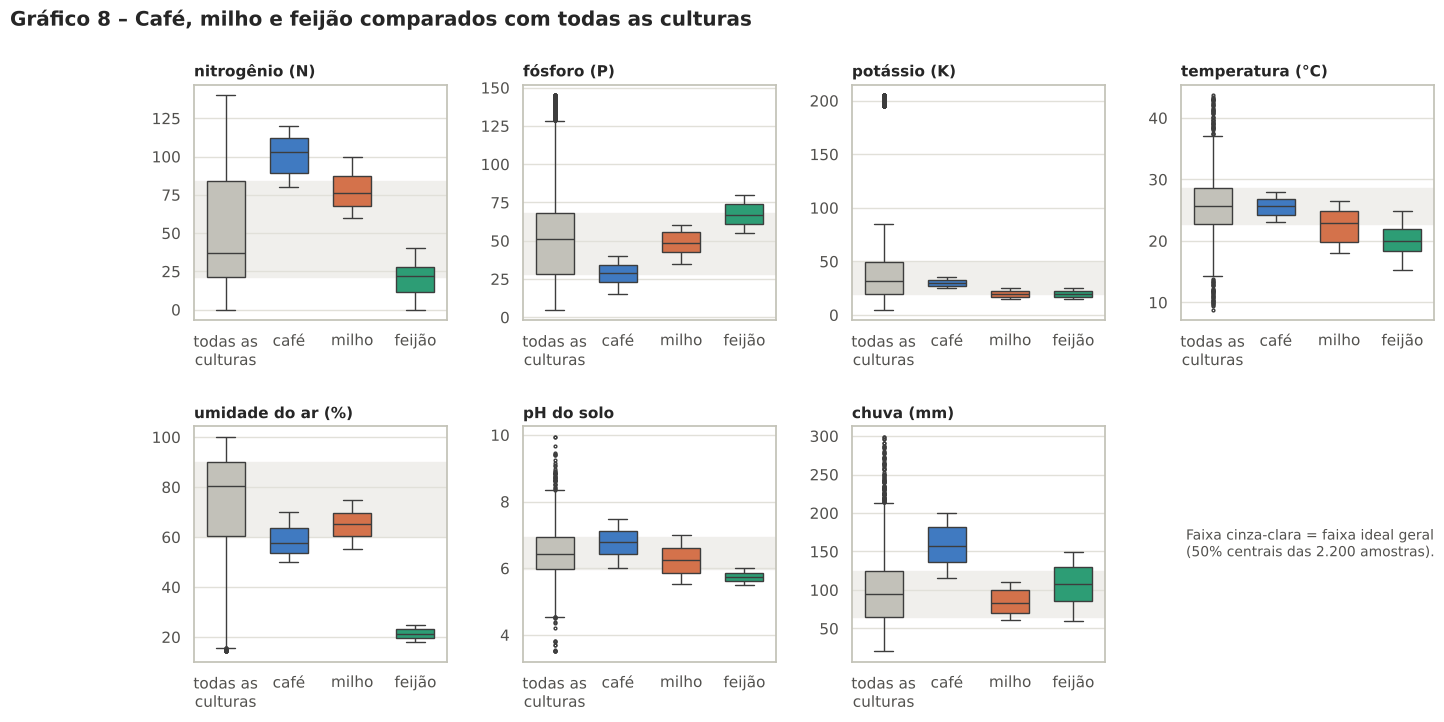

café: distância 2.50 | posição 16 de 22 (1 = mais próxima do perfil geral)
milho: distância 1.42 | posição 3 de 22 (1 = mais próxima do perfil geral)
feijão: distância 3.10 | posição 19 de 22 (1 = mais próxima do perfil geral)


In [19]:
grupos = pd.concat([df.assign(grupo="todas as\nculturas"),
                    df[df["cultura"].isin(ESCOLHIDAS)].assign(grupo=lambda t: t["cultura"])])
ordem_grupos = ["todas as\nculturas"] + ESCOLHIDAS
paleta = {"todas as\nculturas": CINZA, **CORES_DESTAQUE}

fig, eixos = plt.subplots(2, 4, figsize=(16, 7.5), gridspec_kw={"hspace": 0.45, "wspace": 0.3})
for ax, v in zip(eixos.flat, VARIAVEIS):
    ax.axhspan(df[v].quantile(0.25), df[v].quantile(0.75), color=NEUTRO, zorder=0)
    sns.boxplot(data=grupos, x="grupo", y=v, order=ordem_grupos, hue="grupo", palette=paleta, legend=False,
                width=0.6, linewidth=1, fliersize=2, ax=ax)
    ax.set_title(NOMES_PT[v])
    ax.set_xlabel("")
    ax.set_ylabel("")
eixos.flat[-1].axis("off")
eixos.flat[-1].text(0.02, 0.5, "Faixa cinza-clara = faixa ideal geral\n(50% centrais das 2.200 amostras).",
                    fontsize=10, color=TINTA2, va="center")
fig.suptitle("Gráfico 8 – Café, milho e feijão comparados com todas as culturas", x=0.01, ha="left", fontweight="bold")
plt.show()

# Distância de cada cultura ao perfil geral nas 7 variáveis (em desvios-padrão): quanto menor, mais "típica"
distancia = np.sqrt((z_cultura ** 2).sum(axis=1)).sort_values()
for c in ESCOLHIDAS:
    print(f"{c}: distância {distancia[c]:.2f} | posição {distancia.index.get_loc(c) + 1} de 22 (1 = mais próxima do perfil geral)")

### Como café, milho e feijão se comparam com o perfil ideal

Os três perfis diferem entre si em todas as variáveis (Kruskal-Wallis, p < 10⁻³⁰).

- **Café — mais nitrogênio e mais chuva.** N quase triplo (103 contra 37) e chuva de ≈158 mm contra 95 mm, com ar menos úmido (≈58% contra 80%) e menos fósforo (29 contra 51), todos com efeito grande. Temperatura e potássio iguais ao geral; pH um pouco mais alto (6,8; efeito médio).
- **Milho — o mais próximo do perfil geral** (3ª cultura mais próxima entre as 22). Mais N (76) e menos K (20), com clima um pouco mais ameno e seco (≈22,8 °C e 65% de umidade). pH e chuva ficam levemente abaixo do geral, e o fósforo é igual.
- **Feijão — o mais distante dos três** (19ª de 22). Ar muito seco (≈21%, o maior afastamento da comparação), clima ameno (≈20 °C) e solo ácido (pH 5,5 a 6,0); pouco N (22), mais P (67) e menos K (20), todos com efeito grande. A chuva (≈107 mm) é quase a do perfil geral.

**Respostas às perguntas do enunciado:**
- *Preferem mais umidade e mais chuva?* Nenhuma das três quer ar mais úmido que o perfil geral. Só o **café** prefere claramente mais chuva.
- *Preferem mais calor e menos fósforo?* Nenhuma prefere mais calor: o café acompanha a temperatura geral, e milho e feijão preferem clima ameno. Menos fósforo, só o **café**; o feijão pede mais.
- *O que as separa?* O nitrogênio separa café e milho (alto) do feijão (baixo), a umidade isola o feijão e a chuva isola o café.

## 6. Modelos preditivos

### 6.1 Problema, métricas e boas práticas

**Problema:** classificação multiclasse. A partir das 7 condições de solo e clima, o modelo indica a mais adequada entre 22 culturas.

**Métricas:** **F1-macro** como métrica principal (dá o mesmo peso a todas as culturas), **acurácia** (adequada porque as classes são balanceadas), **precisão e recall macro**, **acurácia top-3** (a cultura certa está entre as 3 primeiras sugestões?) e **matriz de confusão**.

**Boas práticas:**
- divisão treino/teste estratificada (80/20) com semente fixa; o teste fica guardado até a avaliação final;
- padronização dentro de *pipelines*, sem vazamento de dados do teste;
- hiperparâmetros escolhidos por busca em grade com validação cruzada estratificada de 5 dobras, usando só o treino;
- baseline ingênuo como ponto de partida;
- campeão escolhido por validação cruzada repetida (5 dobras × 3 repetições);
- checagem de sobreajuste, análise de erros e importância das variáveis.

In [20]:
X = df[VARIAVEIS]
y = df["cultura"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMENTE)
print(f"Treino: {len(X_treino)} amostras | Teste: {len(X_teste)} amostras")
print(f"Amostras por cultura no teste: {y_teste.value_counts().min()} a {y_teste.value_counts().max()}")

Treino: 1760 amostras | Teste: 440 amostras
Amostras por cultura no teste: 20 a 20


In [21]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
pred_baseline = baseline.predict(X_teste)
print(f"Baseline (sempre a mesma cultura): acurácia = {accuracy_score(y_teste, pred_baseline):.3f} | "
      f"F1-macro = {f1_score(y_teste, pred_baseline, average='macro'):.3f}")

Baseline (sempre a mesma cultura): acurácia = 0.045 | F1-macro = 0.004


### 6.2 Os cinco algoritmos

| Algoritmo | Ideia | Padronização |
|---|---|---|
| **Regressão Logística** | fronteiras lineares entre as culturas; referência simples e interpretável | sim |
| **KNN** (k vizinhos mais próximos) | recomenda a cultura das amostras mais parecidas | sim (usa distância) |
| **SVM** com kernel RBF | fronteiras não lineares com margem máxima | sim |
| **Árvore de Decisão** | perguntas em sequência, como "umidade < 30%?"; regras legíveis | não |
| **Random Forest** | votação de centenas de árvores diferentes | não |

In [22]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
modelos = {
    "Regressão Logística": (
        Pipeline([("padronizar", StandardScaler()), ("modelo", LogisticRegression(max_iter=5000))]),
        {"modelo__C": [0.1, 1, 10, 100]}),
    "KNN": (
        Pipeline([("padronizar", StandardScaler()), ("modelo", KNeighborsClassifier())]),
        {"modelo__n_neighbors": [3, 5, 7, 9, 11, 15], "modelo__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (
        Pipeline([("padronizar", StandardScaler()), ("modelo", SVC(kernel="rbf"))]),
        {"modelo__C": [1, 10, 100], "modelo__gamma": ["scale", 0.1, 0.01]}),
    "Árvore de Decisão": (
        DecisionTreeClassifier(random_state=SEMENTE),
        {"max_depth": [None, 8, 12, 16], "min_samples_leaf": [1, 2, 5], "criterion": ["gini", "entropy"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=SEMENTE, n_jobs=-1),
        {"n_estimators": [200, 400], "max_depth": [None, 15], "min_samples_leaf": [1, 2]}),
}

ajustados, linhas = {}, []
for nome, (estimador, grade) in modelos.items():
    inicio = time.perf_counter()
    busca = GridSearchCV(estimador, grade, cv=cv5, scoring="f1_macro", n_jobs=-1)
    busca.fit(X_treino, y_treino)
    ajustados[nome] = busca.best_estimator_
    linhas.append({
        "modelo": nome,
        "melhores hiperparâmetros": ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in busca.best_params_.items()),
        "combinações testadas": len(busca.cv_results_["params"]),
        "tempo da busca (s)": time.perf_counter() - inicio})
pd.DataFrame(linhas).set_index("modelo").round(1)

,melhores hiperparâmetros,combinações testadas,tempo da busca (s)
modelo,,,
Regressão Logística,C=100,4,2.2
KNN,"n_neighbors=3, weights=distance",12,0.5
SVM (RBF),"C=100, gamma=0.01",9,1.2
Árvore de Decisão,"criterion=gini, max_depth=12, min_samples_leaf=1",24,1.3
Random Forest,"max_depth=None, min_samples_leaf=1, n_estimato...",8,20.3


### 6.3 Comparação dos modelos

Cada modelo, já com os melhores hiperparâmetros, passa por validação cruzada **repetida** (5 dobras × 3 repetições = 15 avaliações no treino). O campeão é o de maior média; o teste entra depois, como confirmação independente.

In [23]:
cv_repetida = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMENTE)
notas_cv = pd.DataFrame({nome: cross_val_score(modelo, X_treino, y_treino, cv=cv_repetida, scoring="f1_macro", n_jobs=-1)
                         for nome, modelo in ajustados.items()})
ordem_modelos = notas_cv.mean().sort_values(ascending=False).index.tolist()
campeao = ordem_modelos[0]

def pontuacoes(modelo, X):
    # Probabilidades quando o modelo oferece; senão, a pontuação de decisão (caso do SVM).
    return modelo.predict_proba(X) if hasattr(modelo, "predict_proba") else modelo.decision_function(X)

resultados = []
for nome in ordem_modelos:
    modelo = ajustados[nome]
    pred = modelo.predict(X_teste)
    resultados.append({
        "modelo": nome,
        "acurácia no treino (%)": 100 * accuracy_score(y_treino, modelo.predict(X_treino)),
        "F1-macro validação 5x3 (%)": 100 * notas_cv[nome].mean(),
        "desvio validação (p.p.)": 100 * notas_cv[nome].std(),
        "acurácia teste (%)": 100 * accuracy_score(y_teste, pred),
        "precisão macro teste (%)": 100 * precision_score(y_teste, pred, average="macro"),
        "recall macro teste (%)": 100 * recall_score(y_teste, pred, average="macro"),
        "F1-macro teste (%)": 100 * f1_score(y_teste, pred, average="macro"),
        "top-3 teste (%)": 100 * top_k_accuracy_score(y_teste, pontuacoes(modelo, X_teste), k=3, labels=modelo.classes_),
        "erros no teste (de 440)": int((pred != y_teste).sum())})
tabela_resultados = pd.DataFrame(resultados).set_index("modelo")
print(f"Modelo campeão pela validação cruzada: {campeao}")
tabela_resultados.round(2)

Modelo campeão pela validação cruzada: Random Forest


,acurácia no treino (%),F1-macro validação 5x3 (%),desvio validação (p.p.),acurácia teste (%),precisão macro teste (%),recall macro teste (%),F1-macro teste (%),top-3 teste (%),erros no teste (de 440)
modelo,,,,,,,,,
Random Forest,100.00,99.39,0.30,99.77,99.78,99.77,99.77,100.00,1
SVM (RBF),99.09,98.67,0.53,99.32,99.37,99.32,99.32,100.00,3
Árvore de Decisão,99.60,98.33,0.58,98.64,98.70,98.64,98.65,98.64,6
Regressão Logística,98.98,97.96,0.78,98.64,98.68,98.64,98.64,100.00,6
KNN,100.00,97.49,0.84,98.41,98.46,98.41,98.41,99.32,7


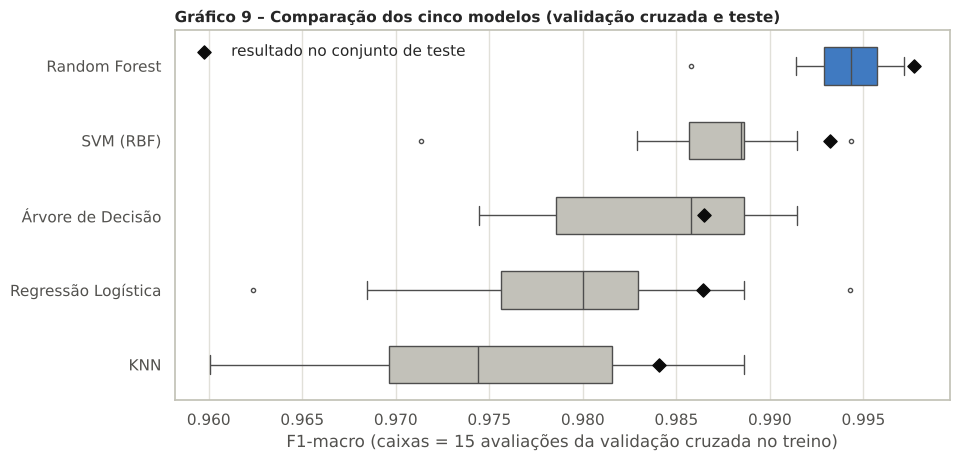

In [24]:
longo = notas_cv.melt(var_name="modelo", value_name="F1-macro")
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.boxplot(data=longo, y="modelo", x="F1-macro", order=ordem_modelos, hue="modelo",
            palette={m: (AZUL if m == campeao else CINZA) for m in ordem_modelos}, legend=False,
            width=0.5, linewidth=1, fliersize=3, ax=ax)
ax.scatter(tabela_resultados.loc[ordem_modelos, "F1-macro teste (%)"] / 100, range(len(ordem_modelos)), marker="D", s=45,
           color="#0b0b0b", zorder=4, label="resultado no conjunto de teste")
ax.set_ylabel("")
ax.set_xlabel("F1-macro (caixas = 15 avaliações da validação cruzada no treino)")
ax.set_title("Gráfico 9 – Comparação dos cinco modelos (validação cruzada e teste)")
ax.legend(loc="upper left")
plt.show()

**Resultado da comparação:**
- **Todos superam com folga o baseline** (4,5% de acurácia): o pior modelo acerta mais de 98% no teste.
- **Campeão: Random Forest**, com a maior média na validação repetida (F1-macro de 99,39% ± 0,30 p.p.) e **99,77% de acurácia no teste (1 erro em 440)**. Em seguida vêm SVM (98,67% na validação; 99,32% no teste), Árvore de Decisão (98,33%; 98,64%), Regressão Logística (97,96%; 98,64%) e KNN (97,49%; 98,41%).
- **As diferenças são pequenas:** menos de 2 p.p. entre o melhor e o pior, e no teste cada erro vale 0,23 p.p. Por isso o campeão foi escolhido pela validação repetida; o teste confirmou a mesma ordem.
- **Sem sobreajuste relevante:** a diferença entre treino e teste fica abaixo de 1,6 p.p. em todos os modelos.
- **Top-3:** Random Forest, SVM e Regressão Logística acertam 100%. A Árvore de Decisão fica em 98,64%, porque uma árvore isolada raramente oferece boas segundas opções.

### 6.4 O modelo campeão em detalhe

Relatório do campeão no teste (20 amostras por cultura). A tabela mostra só as culturas com algum erro e as médias; as demais tiveram 100% em todas as métricas.

In [25]:
melhor = ajustados[campeao]
pred_melhor = melhor.predict(X_teste)
relatorio = pd.DataFrame(classification_report(y_teste, pred_melhor, output_dict=True)).T
acuracia_campeao = relatorio.loc["accuracy", "precision"]
relatorio = relatorio.drop(index="accuracy").rename(
    columns={"precision": "precisão (%)", "recall": "recall (%)", "f1-score": "F1 (%)", "support": "amostras"})
relatorio[["precisão (%)", "recall (%)", "F1 (%)"]] *= 100
relatorio["amostras"] = relatorio["amostras"].astype(int)
com_erro = relatorio[(relatorio["F1 (%)"] < 100) | relatorio.index.str.contains("avg")]
print(f"{campeao} no conjunto de teste: acurácia de {acuracia_campeao:.2%} | "
      f"{(relatorio.drop(index=['macro avg', 'weighted avg'])['F1 (%)'] == 100).sum()} de 22 culturas com 100%")
com_erro.round(1)

Random Forest no conjunto de teste: acurácia de 99.77% | 20 de 22 culturas com 100%


,precisão (%),recall (%),F1 (%),amostras
feijão-moth,100.0,95.0,97.4,20
lentilha,95.2,100.0,97.6,20
macro avg,99.8,99.8,99.8,440
weighted avg,99.8,99.8,99.8,440


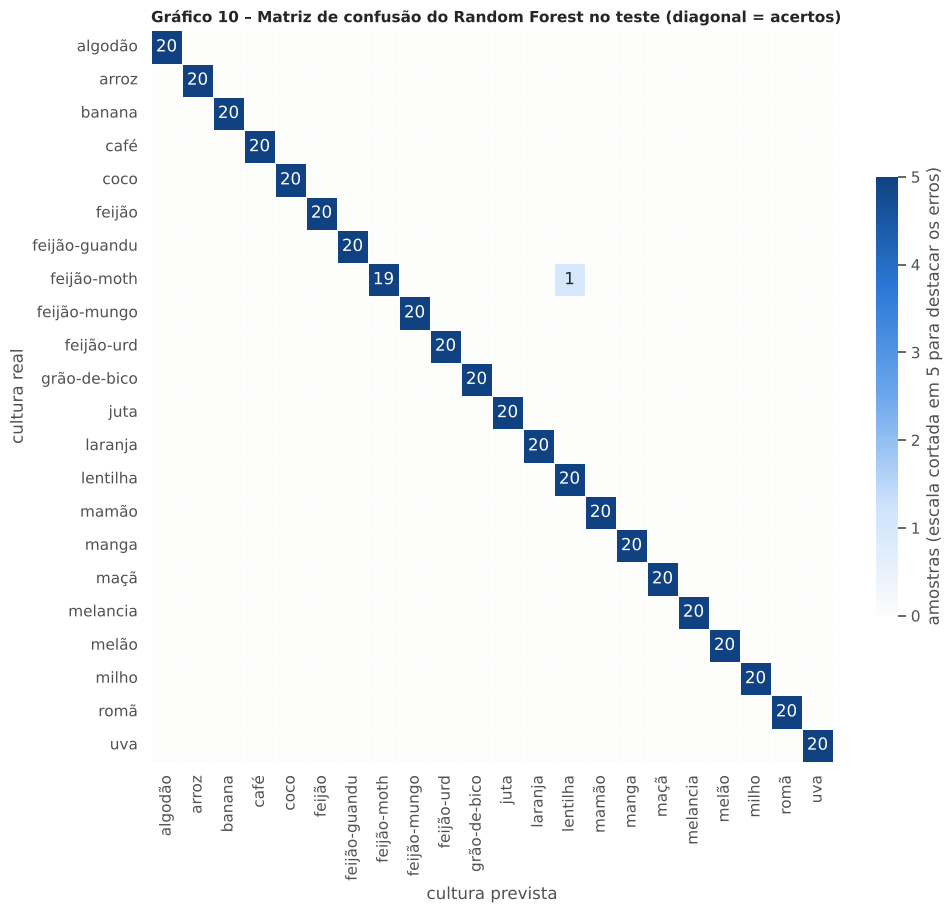

In [26]:
classes = melhor.classes_
matriz = pd.DataFrame(confusion_matrix(y_teste, pred_melhor, labels=classes), index=classes, columns=classes)
anotacao = matriz.astype(str).where(matriz > 0, "")
fig, ax = plt.subplots(figsize=(11, 9.5))
sns.heatmap(matriz, annot=anotacao.values, fmt="", cmap=SEQUENCIAL, vmin=0, vmax=5, linewidths=0.6, linecolor="white",
            cbar_kws={"shrink": 0.6, "label": "amostras (escala cortada em 5 para destacar os erros)"}, ax=ax)
ax.grid(False)
ax.set_xlabel("cultura prevista")
ax.set_ylabel("cultura real")
ax.set_title(f"Gráfico 10 – Matriz de confusão do {campeao} no teste (diagonal = acertos)")
plt.show()

### 6.5 Onde os modelos erram

Todos os erros dos cinco modelos no teste, no formato cultura real → cultura prevista.

In [27]:
erros = []
for nome in ordem_modelos:
    pred = ajustados[nome].predict(X_teste)
    erros += [{"modelo": nome, "real → previsto": f"{r} → {p}"} for r, p in zip(y_teste, pred) if r != p]
(pd.DataFrame(erros).value_counts().unstack("modelo").fillna(0).astype(int)
   .reindex(columns=ordem_modelos).assign(total=lambda t: t.sum(axis=1)).sort_values("total", ascending=False))

modelo,Random Forest,SVM (RBF),Árvore de Decisão,Regressão Logística,KNN,total
real → previsto,,,,,,
feijão-moth → lentilha,1,0,3,0,2,6
café → juta,0,1,0,1,1,3
milho → algodão,0,1,0,1,1,3
arroz → juta,0,1,0,1,0,2
lentilha → feijão-moth,0,0,1,0,1,2
feijão-urd → feijão-moth,0,0,2,0,0,2
feijão-guandu → feijão,0,0,0,1,1,2
feijão → feijão-moth,0,0,0,1,0,1
juta → arroz,0,0,0,1,0,1


**Os erros acontecem entre culturas de perfil parecido:**
- **feijão-moth ↔ lentilha ↔ feijão-urd:** leguminosas de pouca chuva (≈47 a 68 mm), potássio baixo e pH neutro a alcalino. É o único erro do Random Forest e a causa dos 6 erros da Árvore de Decisão;
- **café → juta** e **arroz ↔ juta:** muita chuva e nitrogênio alto;
- **milho → algodão:** potássio baixo e temperatura parecida; o que os separa é o nitrogênio (76 contra 117) e a umidade (65% contra 80%);
- **feijão-guandu → feijão:** solo ácido e fósforo alto.

Quando o modelo hesita, é entre culturas agronomicamente vizinhas, e sugerir as 3 primeiras opções cobre esses casos.

### 6.6 O que o modelo campeão aprendeu

A **importância por permutação** embaralha uma variável de cada vez no teste e mede quanto o F1-macro piora: quanto maior a queda, mais o modelo depende da variável.

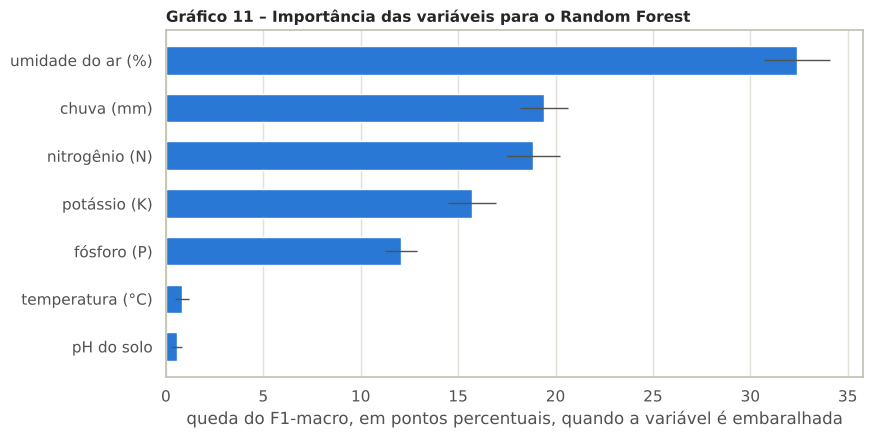

,queda do F1-macro (p.p.),desvio (p.p.)
umidade do ar (%),32.4,1.7
chuva (mm),19.4,1.2
nitrogênio (N),18.8,1.4
potássio (K),15.7,1.2
fósforo (P),12.1,0.8
temperatura (°C),0.8,0.4
pH do solo,0.5,0.3


In [28]:
importancia = permutation_importance(melhor, X_teste, y_teste, n_repeats=15, random_state=SEMENTE,
                                     scoring="f1_macro", n_jobs=-1)
imp = pd.DataFrame({"queda do F1-macro (p.p.)": 100 * importancia.importances_mean,
                    "desvio (p.p.)": 100 * importancia.importances_std}, index=[NOMES_PT[v] for v in VARIAVEIS])
imp = imp.sort_values("queda do F1-macro (p.p.)")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.index, imp["queda do F1-macro (p.p.)"], xerr=imp["desvio (p.p.)"], color=AZUL, height=0.6,
        error_kw={"ecolor": TINTA2, "lw": 1})
ax.grid(axis="y", visible=False)
ax.set_xlabel("queda do F1-macro, em pontos percentuais, quando a variável é embaralhada")
ax.set_title(f"Gráfico 11 – Importância das variáveis para o {campeao}")
plt.show()
imp.sort_values("queda do F1-macro (p.p.)", ascending=False).round(1)

**A umidade do ar é a variável mais decisiva** (o F1-macro cai ≈32 p.p. quando ela é embaralhada), seguida de **chuva** e **nitrogênio** (≈19 p.p. cada), **potássio** (≈16) e **fósforo** (≈12). Temperatura e pH quase não pesam (menos de 1 p.p.): não por serem irrelevantes para as plantas, mas porque a informação deles já está nas outras variáveis. A ordem confirma o Gráfico 5.

### 6.7 Usando o modelo: recomendação para novos talhões

A função recebe as condições de um talhão e devolve as **3 culturas mais indicadas**, com a probabilidade estimada pelo modelo.

In [29]:
modelo_recomendacao = melhor if hasattr(melhor, "predict_proba") else ajustados["Random Forest"]

def recomendar(N, P, K, temperatura, umidade, ph, chuva, k=3):
    entrada = pd.DataFrame([[N, P, K, temperatura, umidade, ph, chuva]], columns=VARIAVEIS)
    prob = pd.Series(modelo_recomendacao.predict_proba(entrada)[0], index=modelo_recomendacao.classes_)
    return prob.sort_values(ascending=False).head(k)

talhoes = {
    "A: muito N, chuvoso, ar moderado": dict(N=100, P=28, K=30, temperatura=25.5, umidade=58, ph=6.8, chuva=160),
    "B: N médio-alto, ameno, pouco K": dict(N=78, P=48, K=20, temperatura=22.5, umidade=65, ph=6.2, chuva=85),
    "C: ar seco, frio, solo ácido": dict(N=20, P=65, K=20, temperatura=20, umidade=22, ph=5.8, chuva=100),
    "D: exatamente o perfil geral": dict(N=37, P=51, K=32, temperatura=25.6, umidade=80.5, ph=6.43, chuva=95),
}
pd.DataFrame({nome: [f"{c} ({p:.1%})" if p >= 0.01 else "—" for c, p in recomendar(**cond).items()]
              for nome, cond in talhoes.items()},
             index=["1ª opção", "2ª opção", "3ª opção"]).T

,1ª opção,2ª opção,3ª opção
"A: muito N, chuvoso, ar moderado",café (100.0%),—,—
"B: N médio-alto, ameno, pouco K",milho (100.0%),—,—
"C: ar seco, frio, solo ácido",feijão (99.5%),—,—
D: exatamente o perfil geral,mamão (16.0%),feijão-mungo (12.0%),manga (11.5%)


- **A, B e C** têm condições dentro das faixas de café, milho e feijão, e o modelo recomenda essas culturas com praticamente 100% de confiança.
- **D**, exatamente no perfil ideal geral, recebe recomendações fracas e divididas (11,5% a 16%). O perfil geral é uma régua de comparação, não o perfil ótimo de nenhuma cultura: cada cultura tem o seu nicho.

## 7. Conclusões

### Principais achados
1. A base é limpa e balanceada; os valores extremos representam culturas exigentes e foram mantidos.
2. As variáveis são quase independentes; a correlação de 0,74 entre P e K vem só de maçã e uva.
3. **Umidade do ar, chuva e nitrogênio** são as variáveis que mais separam as culturas, tanto na análise descritiva quanto no modelo.
4. **Perfil ideal geral:** N ≈ 37, P ≈ 51, K ≈ 32, 25,6 °C, 80% de umidade, pH 6,4 e 95 mm de chuva. O **café** pede mais N e chuva, com ar menos úmido; o **milho** é o mais próximo do geral; o **feijão** é o mais distante (ar seco, clima ameno e solo ácido). As diferenças são estatisticamente significativas, com efeitos em geral médios a grandes.
5. Os cinco modelos passaram de 98% de acurácia no teste, contra 4,5% do baseline. O **Random Forest** foi o melhor: 99,4% de F1-macro na validação cruzada e 99,8% de acurácia no teste. Os poucos erros ocorreram entre culturas vizinhas.

### Pontos fortes
- Processo de Machine Learning com boas práticas: teste isolado, pipelines sem vazamento, busca de hiperparâmetros com validação cruzada, baseline, análise de erros e interpretação.
- Perfil ideal apoiado em testes estatísticos e tamanho de efeito, e não só em médias.
- Função de recomendação pronta para uso, com as 3 culturas mais indicadas e suas probabilidades.

### Limitações
- **Dados ideais, não de campo:** 100 amostras por cultura e faixas bem delimitadas indicam dados montados a partir de recomendações agronômicas. Com dados reais (ruído de sensor, anos atípicos), a acurácia tende a ficar abaixo dos 98% a 99,8% obtidos aqui.
- **Contexto incompleto:** a base não informa as unidades de N, P e K nem o período da chuva, e não traz região, época de plantio, tipo de solo nem dados econômicos.
- **Origem provavelmente indiana:** culturas como juta e feijão-urd são típicas da Índia; para uso no Brasil, o modelo precisa ser recalibrado com dados locais (Embrapa, IBGE).
- **Compatibilidade não é produtividade:** o modelo indica a cultura mais compatível com as condições, não a mais rentável.
- **Seleção de modelos:** hiperparâmetros e comparação usaram o mesmo conjunto de treino; uma validação cruzada aninhada seria mais rigorosa. O teste independente confirmou a ordem dos modelos.

### Próximos passos
- Integrar o modelo aos sensores da FarmTech (umidade, pH e N, P e K do sistema de irrigação) e a dados reais de clima.
- Treinar com dados brasileiros e culturas regionais.
- Incluir produtividade e preço para recomendar a cultura mais rentável.

## Referências
- Base `produtos_agricolas.csv` fornecida pela FIAP (Fase 3, Cap. 11), com a mesma estrutura do conjunto público *Crop Recommendation Dataset*, disponível no Kaggle.
- Documentação do scikit-learn: validação cruzada, `GridSearchCV`, `Pipeline` e importância por permutação (scikit-learn.org).
- ROMANO, J. et al. *Appropriate statistics for ordinal level data*. Florida Association of Institutional Research, 2006 (faixas de interpretação do delta de Cliff).